# DataVisualisation-TP2025 — TP3

[Teacher assignment](https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP3/TP3.md)

Run the cells from top to bottom. The required answers appear at the end. The repository also contains `EXPLICATION_AR.md` with the complete Arabic explanation. Data are included locally or downloaded from their original sources.

## Install the required libraries if needed

In [1]:
import importlib.util
import subprocess
import sys
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


## 1. Load the real UCI dataset and inspect it

In [2]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA = ROOT / "data" / "Metro_Interstate_Traffic_Volume.csv.gz"
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)
URL = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"
if not DATA.exists():
    with urlopen(URL, timeout=60) as response:
        with ZipFile(BytesIO(response.read())) as archive:
            DATA.parent.mkdir(parents=True, exist_ok=True)
            DATA.write_bytes(archive.read("Metro_Interstate_Traffic_Volume.csv.gz"))
# 'None' is a real holiday category, not a missing-value marker.
df = pd.read_csv(DATA, keep_default_na=False, parse_dates=["date_time"])
print(df.head().to_string(index=False))
df.info()
print(df.describe(include="all").to_string())
print("Numerical description:\n", df.describe().to_string())

holiday   temp  rain_1h  snow_1h  clouds_all weather_main weather_description           date_time  traffic_volume
   None 288.28      0.0      0.0          40       Clouds    scattered clouds 2012-10-02 09:00:00            5545
   None 289.36      0.0      0.0          75       Clouds       broken clouds 2012-10-02 10:00:00            4516
   None 289.58      0.0      0.0          90       Clouds     overcast clouds 2012-10-02 11:00:00            4767
   None 290.13      0.0      0.0          90       Clouds     overcast clouds 2012-10-02 12:00:00            5026
   None 291.14      0.0      0.0          75       Clouds       broken clouds 2012-10-02 13:00:00            4918
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              48204 non-null  object        
 1   temp                 48204 non-n

## 2. Overall summary, shape, and grouped weather statistics

In [3]:
traffic = df["traffic_volume"]
mean = float(traffic.mean())
median = float(traffic.median())
mode = traffic.mode().tolist()
std = float(traffic.std())
value_range = int(traffic.max() - traffic.min())
skewness = float(traffic.skew())
kurtosis = float(traffic.kurt()) # excess kurtosis: normal distribution = 0
q1, q3 = traffic.quantile([0.25, 0.75])
iqr = float(q3 - q1)
print({"mean": mean, "median": median, "mode": mode, "std": std,
       "range": value_range, "skewness": skewness, "excess_kurtosis": kurtosis, "IQR": iqr})
weather_summary = df.groupby("weather_main")["traffic_volume"].agg(["mean", "std", "count"])
holiday_summary = df.groupby("holiday")["traffic_volume"].agg(["median", "std", "count"])
print("Weather summary:\n", weather_summary)
print("Holiday summary:\n", holiday_summary)
weather_summary.to_csv(OUT / "weather_summary.csv")
holiday_summary.to_csv(OUT / "holiday_summary.csv")

{'mean': 3259.8183553232097, 'median': 3380.0, 'mode': [353, 356], 'std': 1986.8606704463589, 'range': 7280, 'skewness': -0.08938135143647917, 'excess_kurtosis': -1.3090882117269556, 'IQR': 3740.0}
Weather summary:
                      mean          std  count
weather_main                                 
Clear         3055.908819  1987.101411  13391
Clouds        3618.449749  1906.202879  15164
Drizzle       3290.727073  1997.901830   1821
Fog           2703.720395  2125.525863    912
Haze          3502.101471  1873.511057   1360
Mist          2932.956639  2073.025670   5950
Rain          3317.905501  1982.228705   5672
Smoke         3237.650000  1978.015893     20
Snow          3016.844228  1900.185883   2876
Squall        2061.750000  1950.070490      4
Thunderstorm  3001.620890  1988.296012   1034
Holiday summary:
                            median          std  count
holiday                                              
Christmas Day               767.5   145.988698      6
Columb

## 3. Histogram, overall box plot, and all holiday category box plots

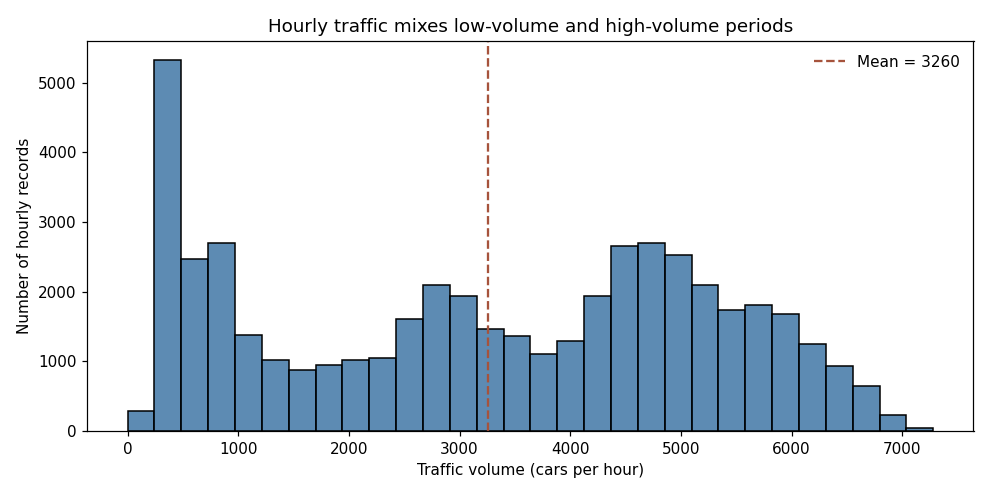

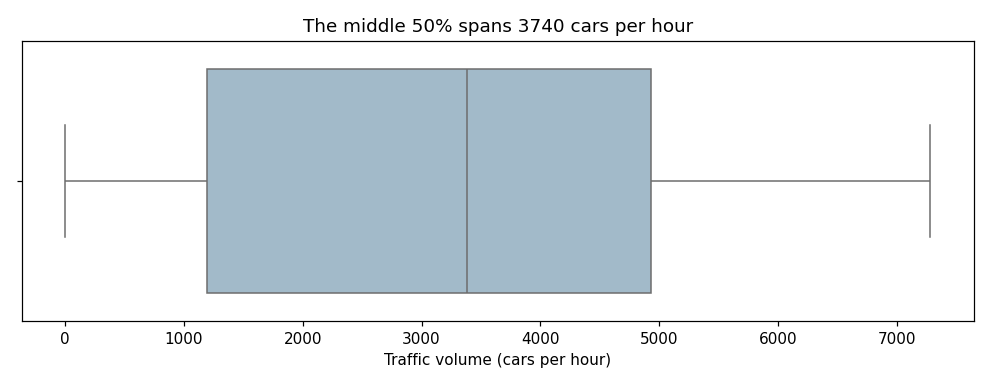

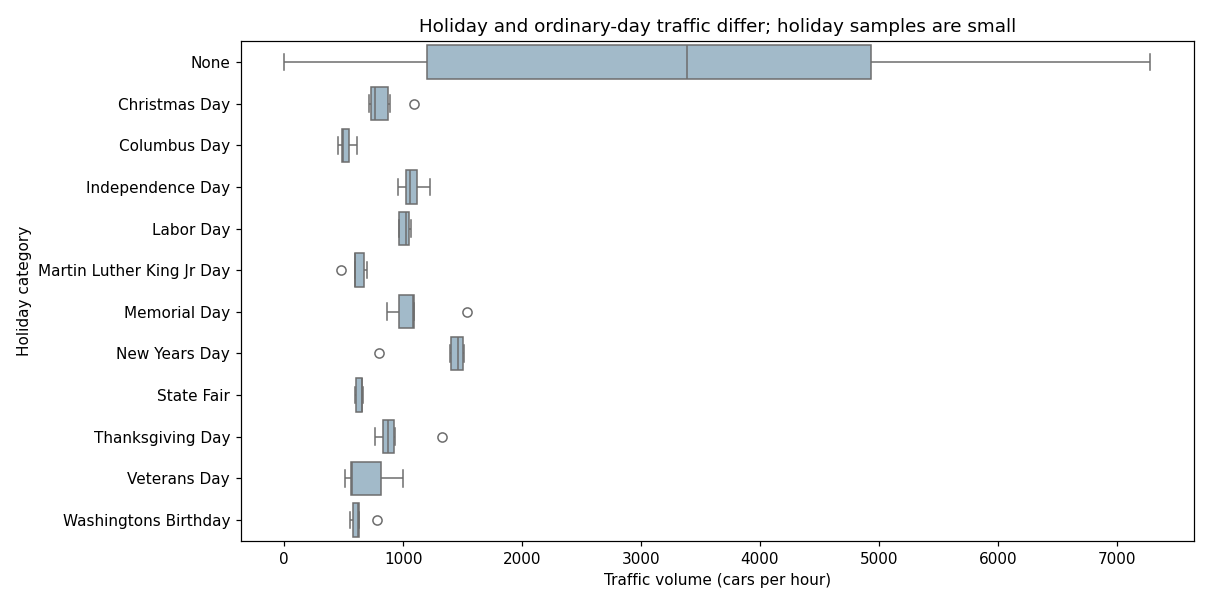

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(traffic, bins=30, ax=ax, color="#27659a")
ax.axvline(mean, color="#a6533c", linestyle="--", label=f"Mean = {mean:.0f}")
ax.set(title="Hourly traffic mixes low-volume and high-volume periods",
       xlabel="Traffic volume (cars per hour)", ylabel="Number of hourly records")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "01_histogram.png", dpi=140)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=traffic, ax=ax, color="#9bbbd0")
ax.set(title=f"The middle 50% spans {iqr:.0f} cars per hour", xlabel="Traffic volume (cars per hour)")
fig.tight_layout()
fig.savefig(OUT / "02_boxplot.png", dpi=140)
plt.show()
plt.close(fig)

holiday_order = ["None"] + sorted(name for name in df["holiday"].unique() if name != "None")
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df, y="holiday", x="traffic_volume", order=holiday_order,
            color="#9bbbd0", ax=ax)
ax.set(title="Holiday and ordinary-day traffic differ; holiday samples are small",
       xlabel="Traffic volume (cars per hour)", ylabel="Holiday category")
fig.tight_layout()
fig.savefig(OUT / "03_holiday_boxplots.png", dpi=140)
plt.show()
plt.close(fig)

## 4. Required correlation matrix and annotated heatmap

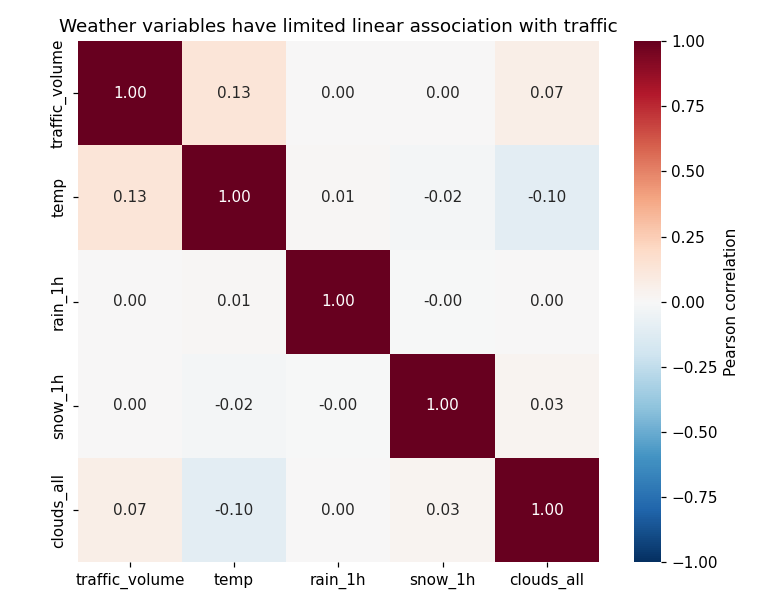

In [5]:
numerical = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all"]
correlation = df[numerical].corr()
environment = correlation.loc["traffic_volume", numerical[1:]]
strongest = environment.abs().idxmax()
strongest_r = float(environment[strongest])
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Weather variables have limited linear association with traffic")
fig.tight_layout()
fig.savefig(OUT / "04_correlation_heatmap.png", dpi=140)
plt.show()
plt.close(fig)
correlation.to_csv(OUT / "correlation.csv")

## 5. Answers to every required interpretation question

In [6]:
highest_mean_weather = weather_summary["mean"].idxmax()
highest_std_weather = weather_summary["std"].idxmax()
anticipated = "negative (left) skew" if mean < median else "positive (right) skew" if mean > median else "symmetry"
shape_description = "negative" if skewness < 0 else "positive"
tail_description = "platykurtic (lower excess kurtosis than normal)" if kurtosis < 0 else "leptokurtic (higher excess kurtosis than normal)"
report = f"""# TP3 — Required EDA answers

Data: {len(df):,} UCI hourly records, kept in their original form for the requested EDA.
The literal holiday value 'None' is preserved as a category. No optional interactive bonus is included.

## Descriptive statistics

Mean: **{mean:.2f}**; median: **{median:.2f}**; mode(s): **{mode}** cars/hour.
Standard deviation: **{std:.2f}**; range: **{value_range}** cars/hour.
The median {'exceeds' if median > mean else 'is below'} the mean, suggesting {anticipated}.
The measured skewness is **{skewness:.4f}** ({shape_description}, modest in magnitude),
which is consistent with that direction; the histogram also reveals a mixture
of low/high traffic periods, so a single skewness value does not describe all its structure.
Excess kurtosis is **{kurtosis:.4f}**: {tail_description}.
Pandas reports excess kurtosis, whose normal reference value is 0, not 3.

Highest weather mean: **{highest_mean_weather}**, {weather_summary.loc[highest_mean_weather,'mean']:.2f}.
Highest weather standard deviation: **{highest_std_weather}**, {weather_summary.loc[highest_std_weather,'std']:.2f}.
Group counts are included because small groups can have unstable summaries.

## Distribution, spread, and holidays

Q1 = **{q1:.2f}**, Q3 = **{q3:.2f}**, IQR = Q3 − Q1 = **{iqr:.2f}** cars/hour.
This large central spread agrees with substantial hourly variability.
All named holiday categories are shown beside ordinary ('None') observations,
with the same neutral color: their medians and spreads can be compared by
position without relying on hue. The grouped table gives actual values/counts.
Ordinary records have standard deviation {holiday_summary.loc['None', 'std']:.2f},
whereas the named-holiday groups range from
{holiday_summary.drop('None')['std'].min():.2f} to {holiday_summary.drop('None')['std'].max():.2f}:
their observed spread is much smaller, and their medians are also lower.
Named holiday samples are sparse and often identify a particular holiday hour,
so apparent differences are descriptive, not proof of a statistically significant
whole-day holiday effect. No unrequested significance test is added.

## Correlation and the causation question

The strongest absolute environmental correlation with traffic is **{strongest}**,
with Pearson r = **{strongest_r:.4f}** ({'positive' if strongest_r > 0 else 'negative'}).
It is still weak, despite being the strongest of the four measured relationships.
Correlation does not establish causation: time of day, commuting schedules,
weekday/weekend differences and season can affect both weather readings and traffic.
For example, daytime can be warmer and busier because people commute, rather
than warmth itself causing traffic. Aggregating these different groups can
mask or alter within-group relationships (the concern behind Simpson's paradox);
this dataset summary alone does not prove an actual reversal.

Assignment: https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP3/TP3.md
Data: https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume
"""
(OUT / "REPORT.md").write_text(report, encoding="utf-8")
print("Strongest correlation:", strongest, strongest_r)
print("Saved the four required plots and answers in", OUT)

Strongest correlation: temp 0.1302987981711253
Saved the four required plots and answers in C:\Users\chikh\Desktop\UNIV\DataVisualisation-TP2025\DataVisualisation-TP2025--TP3\results


## Required written answers

In [7]:
from IPython.display import Markdown, display
display(Markdown((OUT / "REPORT.md").read_text(encoding="utf-8")))

# TP3 — Required EDA answers

Data: 48,204 UCI hourly records, kept in their original form for the requested EDA.
The literal holiday value 'None' is preserved as a category. No optional interactive bonus is included.

## Descriptive statistics

Mean: **3259.82**; median: **3380.00**; mode(s): **[353, 356]** cars/hour.
Standard deviation: **1986.86**; range: **7280** cars/hour.
The median exceeds the mean, suggesting negative (left) skew.
The measured skewness is **-0.0894** (negative, modest in magnitude),
which is consistent with that direction; the histogram also reveals a mixture
of low/high traffic periods, so a single skewness value does not describe all its structure.
Excess kurtosis is **-1.3091**: platykurtic (lower excess kurtosis than normal).
Pandas reports excess kurtosis, whose normal reference value is 0, not 3.

Highest weather mean: **Clouds**, 3618.45.
Highest weather standard deviation: **Fog**, 2125.53.
Group counts are included because small groups can have unstable summaries.

## Distribution, spread, and holidays

Q1 = **1193.00**, Q3 = **4933.00**, IQR = Q3 − Q1 = **3740.00** cars/hour.
This large central spread agrees with substantial hourly variability.
All named holiday categories are shown beside ordinary ('None') observations,
with the same neutral color: their medians and spreads can be compared by
position without relying on hue. The grouped table gives actual values/counts.
Ordinary records have standard deviation 1986.26,
whereas the named-holiday groups range from
31.55 to 277.11:
their observed spread is much smaller, and their medians are also lower.
Named holiday samples are sparse and often identify a particular holiday hour,
so apparent differences are descriptive, not proof of a statistically significant
whole-day holiday effect. No unrequested significance test is added.

## Correlation and the causation question

The strongest absolute environmental correlation with traffic is **temp**,
with Pearson r = **0.1303** (positive).
It is still weak, despite being the strongest of the four measured relationships.
Correlation does not establish causation: time of day, commuting schedules,
weekday/weekend differences and season can affect both weather readings and traffic.
For example, daytime can be warmer and busier because people commute, rather
than warmth itself causing traffic. Aggregating these different groups can
mask or alter within-group relationships (the concern behind Simpson's paradox);
this dataset summary alone does not prove an actual reversal.

Assignment: https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP3/TP3.md
Data: https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume
